# 01 · Corpus Exploration

**Project:** Pasalytics, an IP firm knowledge assistant (Retrieval-Augmented Generation)

**Business problem.** Staff at an IP firm spend a large share of their day looking up deadlines, fees and procedures scattered across SOPs, policies and regulations, or asking senior colleagues the same questions. New joiners take weeks to become productive.

**Goal.** Build an assistant that answers staff questions from the firm's own documents, cites its sources, and says *"I don't know"* instead of guessing.

**Data.**
- 20 internal SOPs and policies of *Lumina IP Partners*, a **fictional** Jakarta IP firm (synthetic documents written for this project).
- Optional: public Indonesian IP regulations (PDF) placed in `data/raw/regulations/`.

This notebook profiles the corpus before chunking.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from src.ingest import load_internal_docs, load_regulations
internal = load_internal_docs()
regs = load_regulations()
docs = internal + regs
print(f"Internal documents: {len(internal)} | Regulations: {len(regs)}")

Internal documents: 20 | Regulations: 0


In [3]:
profile = pd.DataFrame([{
    "doc_id": d.doc_id, "title": d.title, "type": d.source_type,
    "owner": d.metadata.get("owner", "-"),
    "words": len(d.text.split()),
    "sections": d.text.count("\n## ") + (1 if d.text.startswith("## ") else 0),
} for d in docs])
profile["family"] = profile["doc_id"].str.extract(r"^([A-Z]+(?:-[A-Z]+)?)")[0]
profile.sort_values("doc_id")

,doc_id,title,type,owner,words,sections,family
0,GUIDE-COM-01,Client Communication Standards,internal,Client Service,156,5,GUIDE-COM
1,GUIDE-DSP-01,IP Enforcement and Dispute Escalation,internal,Disputes Group,153,5,GUIDE-DSP
2,HR-01,Working Hours and Leave Policy,internal,Human Resources,153,4,HR
3,HR-02,Onboarding and Training for New Staff,internal,Human Resources,136,4,HR
4,POL-BILL-01,Billing and Fee Policy,internal,Finance,185,4,POL-BILL
5,POL-BILL-02,Payment Terms and Collection,internal,Finance,145,4,POL-BILL
6,POL-CL-01,Client Intake and Conflict Check Policy,internal,Risk and Compliance,175,4,POL-CL
7,POL-CONF-01,Confidentiality and Data Protection Policy,internal,Risk and Compliance,178,5,POL-CONF
8,POL-DOC-01,Document Management and File Naming,internal,Operations,103,4,POL-DOC
9,POL-KYC-01,Client Due Diligence and Power of Attorney,internal,Risk and Compliance,161,3,POL-KYC


In [4]:
summary = profile.groupby("family").agg(documents=("doc_id", "count"), words=("words", "sum")).sort_values("words", ascending=False)
summary

,documents,words
family,,
SOP-TM,6,1261
POL-BILL,2,330
SOP-PT,2,326
HR,2,289
POL-CONF,1,178
POL-CL,1,175
POL-KYC,1,161
SOP-ID,1,158
GUIDE-COM,1,156


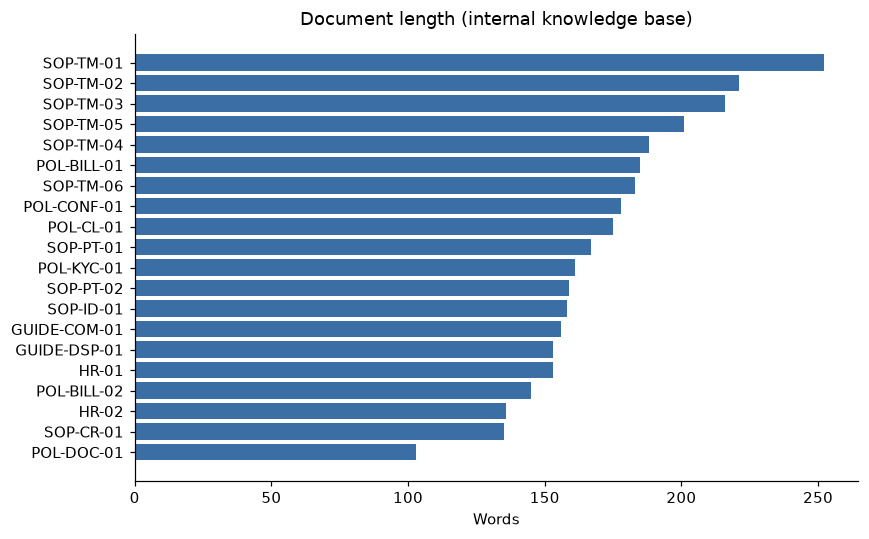

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
p = profile.sort_values("words")
ax.barh(p["doc_id"], p["words"], color="#3b6ea5")
ax.set_xlabel("Words"); ax.set_title("Document length (internal knowledge base)")
plt.tight_layout(); plt.savefig("reports/figures/01_document_length.png"); plt.show()

In [6]:
import re
# How much of the corpus is 'hard facts' (numbers, fees, deadlines)? These are exactly what users ask about.
facts = [(d.doc_id, m) for d in internal for m in re.findall(r"\*\*(.+?)\*\*", d.text)]
facts_df = pd.DataFrame(facts, columns=["doc_id", "fact"])
facts_df["kind"] = np.select(
    [facts_df.fact.str.contains("IDR|USD"), facts_df.fact.str.contains("day|month|year|hour|week", case=False)],
    ["fee", "time / deadline"], "other")
print(f"{len(facts_df)} highlighted facts in the internal documents")
facts_df["kind"].value_counts()

131 highlighted facts in the internal documents


kind
time / deadline    74
fee                31
other              26
Name: count, dtype: int64

### Observations
- The internal corpus is small (~4,000 words) but **dense with exact numbers**: fees and deadlines account for most highlighted facts. A wrong number is the most costly failure, so evaluation must check numbers exactly.
- Documents are well structured with `##` sections, so **section-based chunking** is a natural fit (next notebook).
- Many questions will use different wording from the documents ("object to a mark" vs "opposition"), which motivates combining lexical and semantic search.